In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [4]:

# Load all IndiaKart datasets

folder = r"C:\Users\rajul\India Kart Phase2_EDA"

orders = pd.read_csv(os.path.join(folder, "orders DA.csv"))
customers = pd.read_csv(os.path.join(folder, "customers DA.csv"))
returns = pd.read_csv(os.path.join(folder, "returns DA.csv"))
products = pd.read_csv(os.path.join(folder, "products DA.csv"))
payments = pd.read_csv(os.path.join(folder, "payments DA.csv"))
order_items = pd.read_csv(os.path.join(folder, "order_items DA.csv"))
inventory = pd.read_csv(os.path.join(folder, "inventory DA.csv"))
suppliers = pd.read_csv(os.path.join(folder, "suppliers DA.csv"))

print("All datasets loaded successfully!")
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Returns:", returns.shape)
print("Products:", products.shape)
print("Payments:", payments.shape)
print("Order Items:", order_items.shape)
print("Inventory:", inventory.shape)
print("Suppliers:", suppliers.shape)


All datasets loaded successfully!
Orders: (50000, 19)
Customers: (10000, 17)
Returns: (10000, 10)
Products: (1000, 17)
Payments: (50000, 13)
Order Items: (100000, 11)
Inventory: (1000, 11)
Suppliers: (200, 14)



## KPI 1: Monthly Order Volume

### Objective
Analyze the number of orders placed each month over the available 24-month period.

### Business Questions
- Which months have the highest and lowest order volumes?
- Do orders increase during October and November, around the Diwali festive season?
- Is the monthly order trend consistent across the two years?

### Methodology
Group orders by month and count unique order IDs. Display the results in a bar chart, highlighting October and November.

### Columns Used
- `order_id`: Unique order identifier
- `order_date`: Date the order was placed

### Expected Outcome
Identify monthly peaks, seasonal patterns, and possible changes in order volume during the Diwali period.


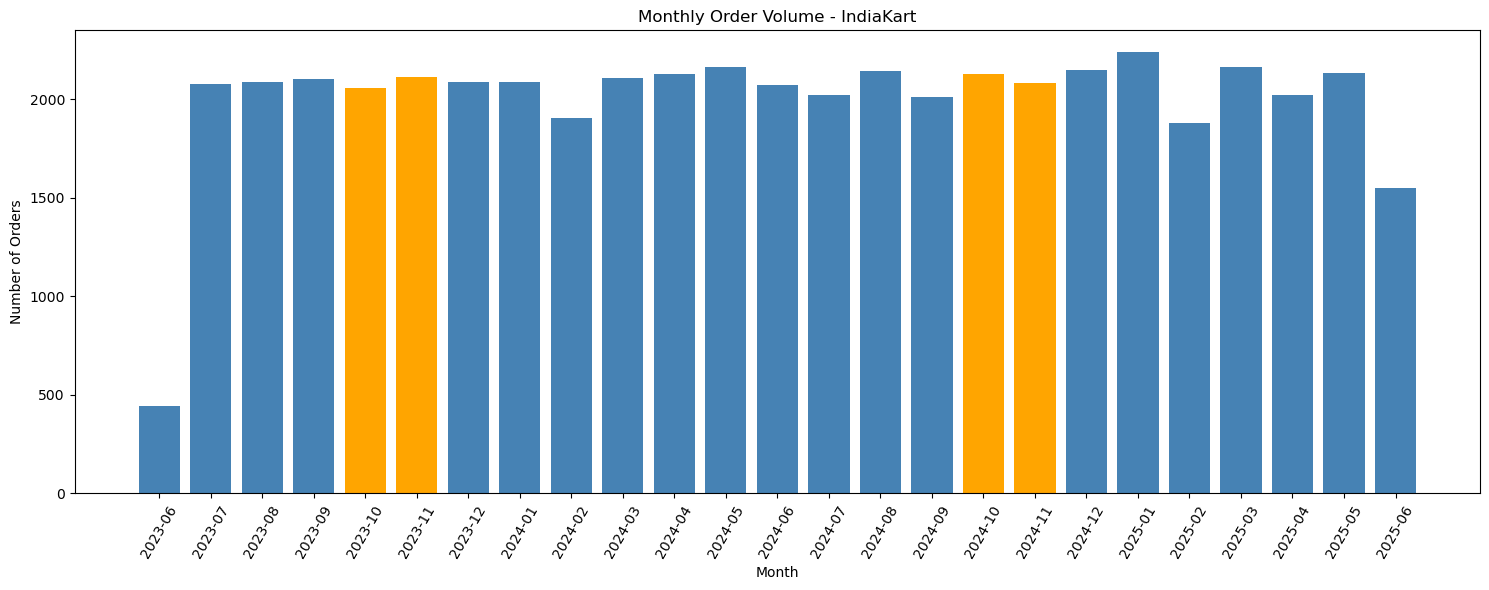

Months analyzed: 25
Busiest month: 2025-01
Highest monthly orders: 2239
Lowest month: 2023-06
Lowest monthly orders: 444


In [9]:

# KPI 1: Monthly Order Volume

# Convert order dates into date format
orders['order_date'] = pd.to_datetime(
    orders['order_date'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Count unique orders for each month
valid_orders = orders.dropna(subset=['order_date']).copy()

monthly_orders = (
    valid_orders
    .groupby(valid_orders['order_date'].dt.to_period('M'))['order_id']
    .nunique()
)

# Include months with zero orders
all_months = pd.period_range(
    monthly_orders.index.min(),
    monthly_orders.index.max(),
    freq='M'
)

monthly_orders = monthly_orders.reindex(all_months, fill_value=0)

# Highlight October and November
colors = [
    'orange' if month.month in [10, 11] else 'steelblue'
    for month in monthly_orders.index
]

# Draw the bar chart
plt.figure(figsize=(15, 6))
plt.bar(monthly_orders.index.astype(str), monthly_orders.values, color=colors)

plt.title('Monthly Order Volume - IndiaKart')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=60)
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI1_Monthly_Order_Volume.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display key results
print("Months analyzed:", len(monthly_orders))
print("Busiest month:", monthly_orders.idxmax())
print("Highest monthly orders:", monthly_orders.max())
print("Lowest month:", monthly_orders.idxmin())
print("Lowest monthly orders:", monthly_orders.min())



### Observations

1. Monthly order volume remained relatively stable across most months, generally ranging between approximately 1,900 and 2,200 orders.

2. January 2025 recorded the highest order volume, with 2,239 orders, while June 2023 recorded the lowest, with 444 orders. June 2023 and June 2025 are partial months and should be interpreted cautiously.

3. October and November are highlighted to assess possible Diwali-related demand changes. The chart does not show a consistent festive-season increase across all years.


## KPI 2: Monthly Revenue (GMV)

### Objective
Analyze monthly revenue using the `final_amount` column over the available period.

### Business Questions
- Which months generate the highest and lowest revenue?
- How does monthly revenue compare between years?
- Does revenue increase during October and November around the Diwali festive season?

### Methodology
Group orders by month and calculate the sum of `final_amount`. Visualize monthly revenue using a line chart and compare the same months across years.

### Columns Used
- `order_date`: Date the order was placed
- `final_amount`: Final amount paid for the order

### Expected Outcome
Identify revenue trends, seasonal patterns, and year-over-year changes in GMV.

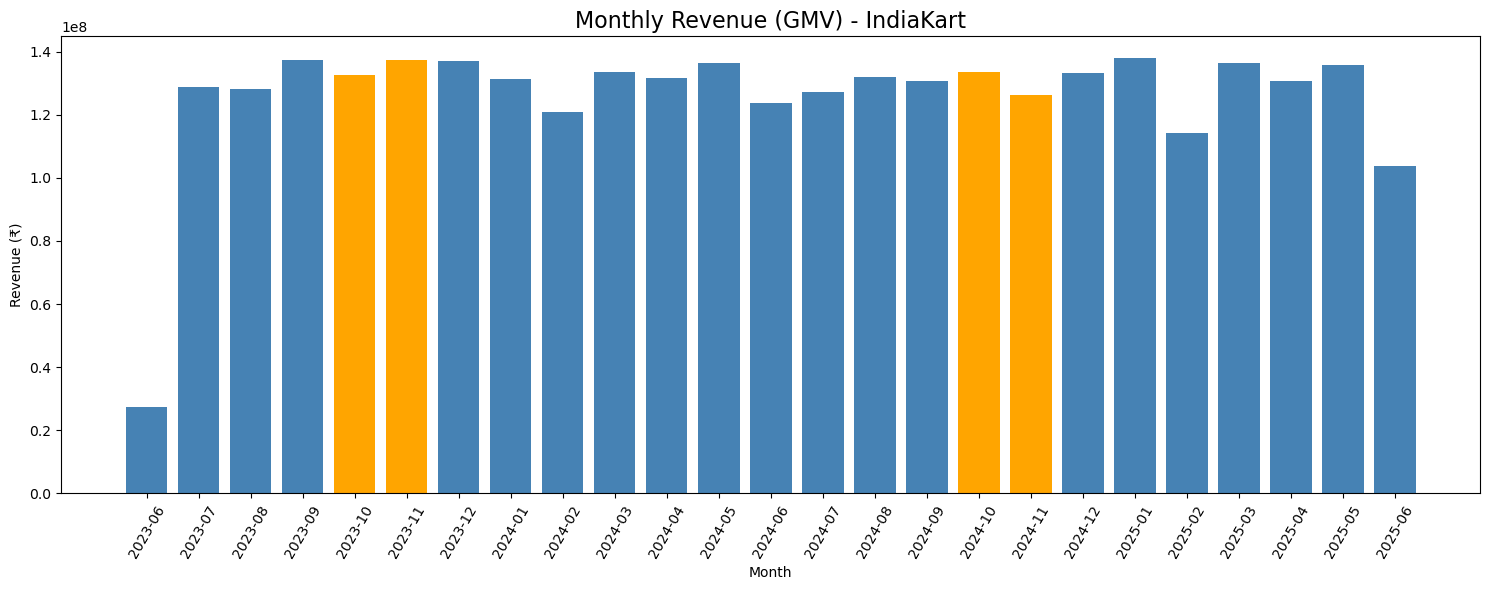

Highest revenue month: 2025-01
Highest monthly revenue: 137929116.81
Lowest revenue month: 2023-06
Lowest monthly revenue: 27384848.52


In [10]:

# KPI 2: Monthly Revenue (GMV)

# Calculate monthly revenue
monthly_revenue = (
    orders.dropna(subset=['order_date'])
    .groupby(orders['order_date'].dt.to_period('M'))['final_amount']
    .sum()
)

# Ensure all months are included
all_months = pd.period_range(
    monthly_revenue.index.min(),
    monthly_revenue.index.max(),
    freq='M'
)

monthly_revenue = monthly_revenue.reindex(all_months, fill_value=0)

# Highlight October and November
colors = [
    'orange' if month.month in [10, 11] else 'steelblue'
    for month in monthly_revenue.index
]

# Create the chart
plt.figure(figsize=(15, 6))
plt.bar(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    color=colors
)

plt.title('Monthly Revenue (GMV) - IndiaKart', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=60)
plt.tight_layout()

# Save the chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI2_Monthly_Revenue_GMV.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display key results
print("Highest revenue month:", monthly_revenue.idxmax())
print("Highest monthly revenue:", round(monthly_revenue.max(), 2))
print("Lowest revenue month:", monthly_revenue.idxmin())
print("Lowest monthly revenue:", round(monthly_revenue.min(), 2))



### Observations

1. Monthly revenue peaked in January 2025 at approximately ₹137.93 million, while June 2023 recorded the lowest revenue at approximately ₹27.38 million. June 2023 is a partial month, so the low value should be interpreted cautiously.

2. Revenue remained relatively high across most full months, generally ranging between approximately ₹120 million and ₹138 million.

3. October and November revenue varied across the two years shown. A consistent Diwali-related increase is not clearly established from this chart alone.


## KPI 3: Category-wise Revenue Share

### Objective
Analyze how total revenue is distributed across product categories.

### Business Questions
- Which product category generates the highest revenue?
- Which categories contribute the least revenue?
- How is revenue distributed across the product portfolio?

### Methodology
Combine order information with order-item and product data to identify the product category associated with each sale. Calculate total revenue by category and display the results using a horizontal bar chart.

### Columns Used
- `order_id`: Order identifier
- `product_id`: Product identifier
- `category`: Product category
- `final_amount`: Final order amount

### Expected Outcome
Identify the highest-revenue categories and understand their contribution to overall sales.

In [11]:

# Check columns for KPI 3

print("ORDER ITEMS columns:")
print(order_items.columns.tolist())

print("\nPRODUCTS columns:")
print(products.columns.tolist())

print("\nOrder items preview:")
display(order_items.head())

print("\nProducts preview:")
display(products.head())


ORDER ITEMS columns:
['item_id', 'order_id', 'product_id', 'product_name', 'category', 'quantity', 'unit_price', 'gst_rate', 'gst_amount', 'discount_amount', 'total_price']

PRODUCTS columns:
['product_id', 'product_name', 'category', 'subcategory', 'brand', 'sku', 'mrp', 'selling_price', 'cost_price', 'gst_rate', 'hsn_code', 'weight_grams', 'supplier_id', 'rating', 'review_count', 'is_active', 'launch_date']

Order items preview:


,item_id,order_id,product_id,product_name,category,quantity,unit_price,gst_rate,gst_amount,discount_amount,total_price
0,ITM0000001,ORD000001,PRD0522,HCL Cricket Bat Ultra,Sports & Fitness,1,40989,12,4918.68,7861.45,38046.23
1,ITM0000002,ORD000001,PRD0094,Berger Router Pro,Electronics,1,62532,18,11255.76,12373.11,61414.65
2,ITM0000003,ORD000001,PRD0613,Voltas Educational Toy Standard,Toys & Baby,1,1585,12,190.20,251.89,1523.31
3,ITM0000004,ORD000002,PRD0556,Ambrane Cycle Standard,Sports & Fitness,3,1107,12,398.52,631.44,3088.08
4,ITM0000005,ORD000002,PRD0026,Pebble Tablet Premium,Electronics,2,114448,18,41201.28,18707.35,251389.93



Products preview:


,product_id,product_name,category,subcategory,brand,sku,mrp,selling_price,cost_price,gst_rate,hsn_code,weight_grams,supplier_id,rating,review_count,is_active,launch_date
0,PRD0001,Usha Smartphone Elite,Electronics,Smartphone,Usha,SKU-ELE-00001,92028,78958,55738,18,1144,250,SUP0198,4.3,3655,1,29-01-2025
1,PRD0002,Gizmore Smartphone Premium,Electronics,Smartphone,Gizmore,SKU-ELE-00002,91470,65917,48052,18,2857,2000,SUP0140,3.6,2321,1,17-05-2024
2,PRD0003,Fire-Boltt Smartphone Max,Electronics,Smartphone,Fire-Boltt,SKU-ELE-00003,148029,118800,68913,18,2349,250,SUP0113,3.5,4412,1,28-12-2024
3,PRD0004,Godrej Smartphone Elite,Electronics,Smartphone,Godrej,SKU-ELE-00004,152903,113203,80055,18,8130,250,SUP0068,4.5,1264,1,04-05-2023
4,PRD0005,HDFC Smartphone Elite,Electronics,Smartphone,HDFC,SKU-ELE-00005,18715,16226,8398,18,4729,1000,SUP0088,3.9,3700,1,27-11-2023


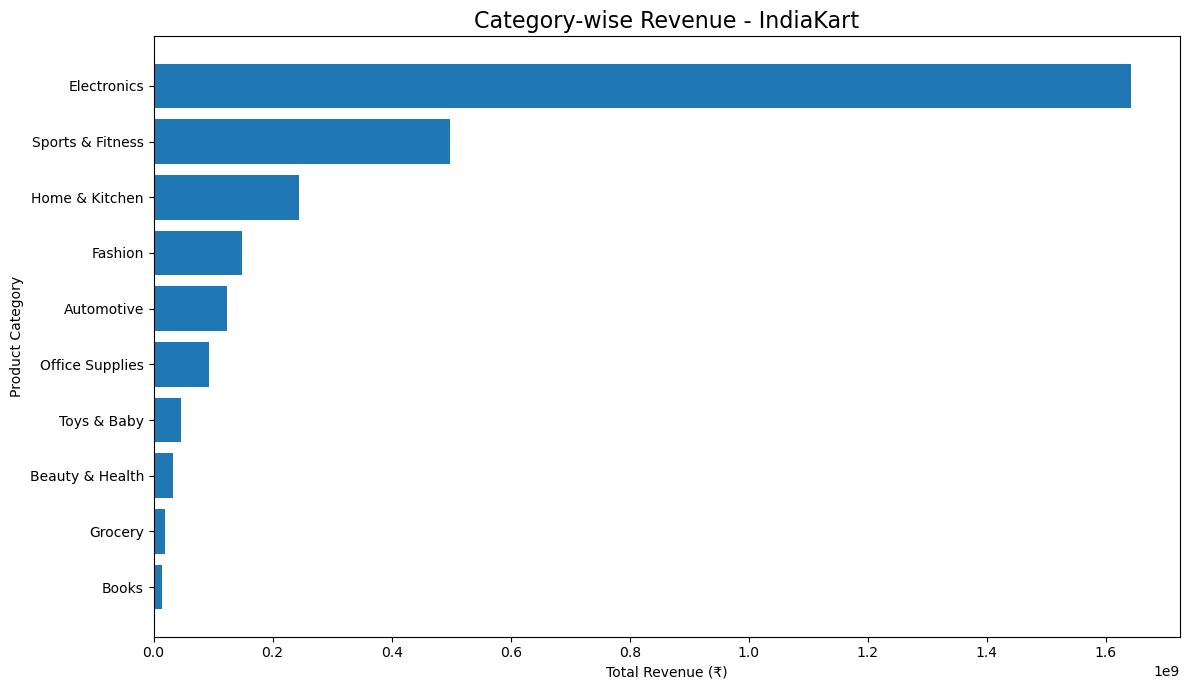

,Total Revenue,Revenue Share (%)
category,,
Electronics,1.642423e+09,57.41
Sports & Fitness,4.972384e+08,17.38
Home & Kitchen,2.442952e+08,8.54
Fashion,1.481553e+08,5.18
Automotive,1.234851e+08,4.32
Office Supplies,9.302935e+07,3.25
Toys & Baby,4.658385e+07,1.63
Beauty & Health,3.301811e+07,1.15
Grocery,1.871868e+07,0.65


Highest revenue category: Electronics
Highest category revenue: 1642422813.39


In [12]:

# KPI 3: Category-wise Revenue Share

# Calculate revenue for each category
category_revenue = (
    order_items.groupby('category')['total_price']
    .sum()
    .sort_values(ascending=True)
)

# Calculate percentage share of total revenue
category_share = (
    category_revenue / category_revenue.sum() * 100
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    category_revenue.index,
    category_revenue.values
)

plt.title('Category-wise Revenue - IndiaKart', fontsize=16)
plt.xlabel('Total Revenue (₹)')
plt.ylabel('Product Category')
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI3_Category_Revenue.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display revenue and percentage share
category_summary = pd.DataFrame({
    'Total Revenue': category_revenue,
    'Revenue Share (%)': category_share
}).sort_values('Total Revenue', ascending=False)

display(category_summary.round(2))

print("Highest revenue category:", category_revenue.idxmax())
print("Highest category revenue:", round(category_revenue.max(), 2))



### Observations

1. Electronics is the highest-revenue category, contributing approximately 57.41% of total item-level revenue. This indicates that Electronics is the main revenue driver in the IndiaKart product portfolio.

2. Sports & Fitness is the second-largest category, contributing 17.38%, followed by Home & Kitchen at 8.54%.

3. Revenue is concentrated in a few categories, with Electronics alone accounting for more than half of total item-level revenue. IndiaKart may benefit from reviewing the performance and growth opportunities of the lower-revenue categories.



## KPI 4: Order Status Distribution

### Objective
Analyze the distribution of orders across different order statuses.

### Business Questions
- What percentage of orders are Delivered?
- How many orders are Cancelled, Returned, Shipped, or Processing?
- What proportion of orders have not reached the Delivered status?

### Methodology
Count the orders in each status and calculate their percentage of total orders. Display the distribution using a donut chart.

### Columns Used
- `order_id`: Unique order identifier
- `status`: Current order status

### Expected Outcome
Understand order completion rates and identify the proportion of orders that may require further processing or follow-up.


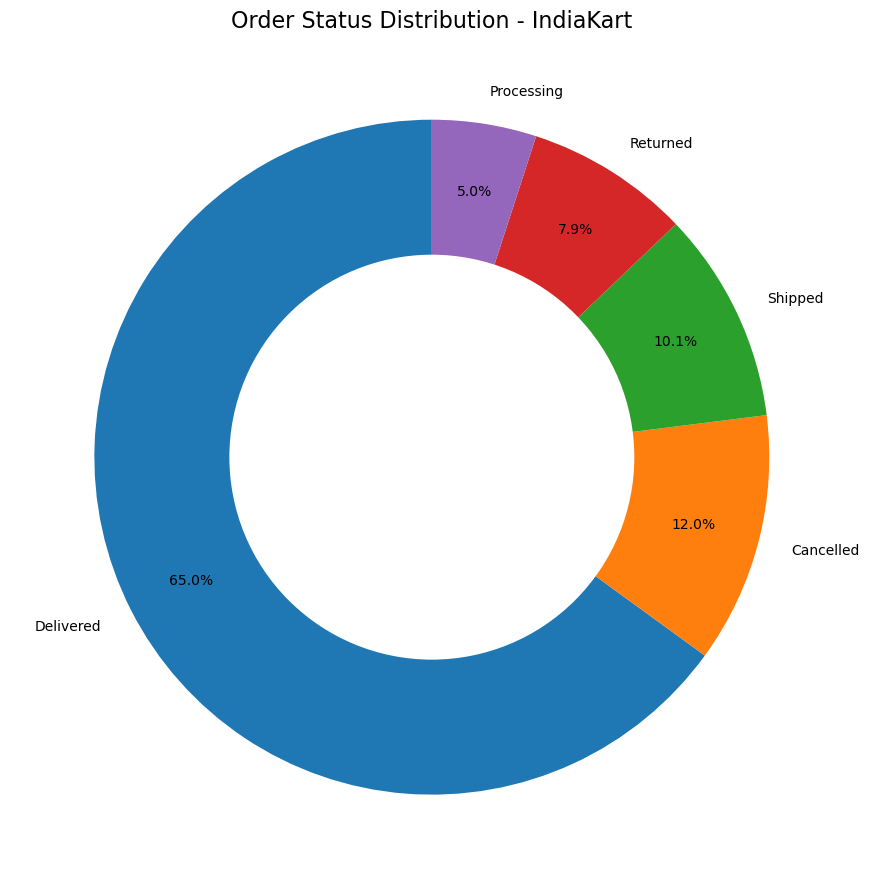

,Order Count,Percentage (%)
status,,
Delivered,32499,65.00
Cancelled,5996,11.99
Shipped,5071,10.14
Returned,3933,7.87
Processing,2501,5.00


In [13]:

# KPI 4: Order Status Distribution

# Count unique orders for each status
status_counts = (
    orders.groupby('status')['order_id']
    .nunique()
    .sort_values(ascending=False)
)

# Calculate percentage of total orders
status_percentages = status_counts / status_counts.sum() * 100

# Create donut chart
plt.figure(figsize=(9, 9))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.80
)

# Create the donut hole
centre_circle = plt.Circle((0, 0), 0.60, fc='white')
plt.gca().add_artist(centre_circle)

plt.title('Order Status Distribution - IndiaKart', fontsize=16)
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI4_Order_Status_Distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display counts and percentages
status_summary = pd.DataFrame({
    'Order Count': status_counts,
    'Percentage (%)': status_percentages
})

display(status_summary.round(2))



### Observations

1. Delivered orders account for 65% of all orders, indicating that most orders have been successfully completed.

2. Cancelled orders represent 11.99%, while returned orders account for 7.87%. These outcomes may warrant further investigation to understand the reasons behind cancellations and returns.

3. Shipped and Processing orders together represent approximately 15.14% of orders. Monitoring these orders can help identify potential delivery delays or processing bottlenecks.



## KPI 5: Top 10 States by Number of Orders

### Objective
Identify the 10 states that generate the highest number of orders.

### Business Questions
- Which states have the highest order volume?
- Which states contribute the least among the top 10?
- Where is customer demand geographically concentrated?

### Methodology
Group orders by state, count unique order IDs, and select the top 10 states. Display the results using a horizontal bar chart.

### Columns Used
- `state`: Customer order state
- `order_id`: Unique order identifier

### Expected Outcome
Identify the states with the strongest order volumes and understand the geographic distribution of demand.


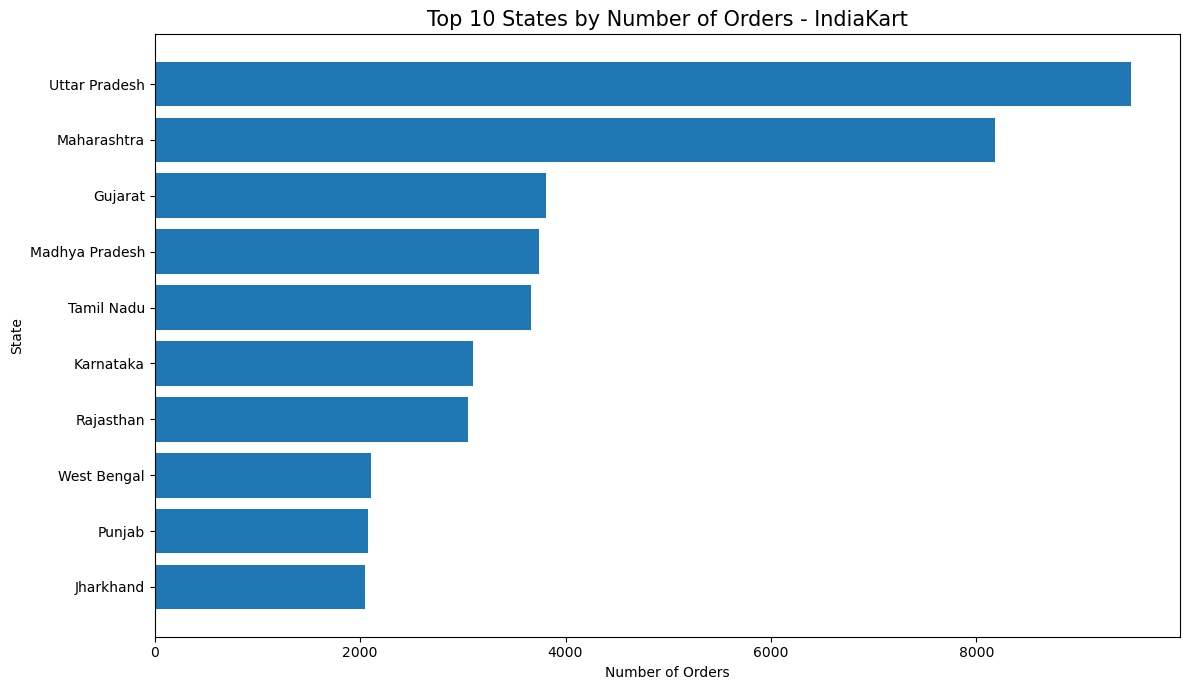

Top 10 states by order volume:


,Number of Orders
state,
Uttar Pradesh,9507
Maharashtra,8179
Gujarat,3811
Madhya Pradesh,3741
Tamil Nadu,3664
Karnataka,3102
Rajasthan,3047
West Bengal,2103
Punjab,2073


In [14]:

# KPI 5: Top 10 States by Number of Orders

# Count unique orders for each state
state_orders = (
    orders.groupby('state')['order_id']
    .nunique()
    .sort_values(ascending=False)
)

# Select the top 10 states
top_10_states = state_orders.head(10).sort_values(ascending=True)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_states.index,
    top_10_states.values
)

plt.title('Top 10 States by Number of Orders - IndiaKart', fontsize=15)
plt.xlabel('Number of Orders')
plt.ylabel('State')
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI5_Top10_States.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display the results
print("Top 10 states by order volume:")
display(top_10_states.sort_values(ascending=False).to_frame(
    name='Number of Orders'
))



### Observations

1. Uttar Pradesh leads the top 10 states with 9,507 orders, followed by Maharashtra with 8,179 orders. These states represent the strongest order volumes in the dataset.

2. There is a noticeable gap between Maharashtra and Gujarat, which ranks third with 3,811 orders. This suggests that order demand is concentrated in the two leading states.

3. Jharkhand has the lowest order volume among the top 10 states, with 2,044 orders. IndiaKart could investigate regional demand and customer acquisition opportunities across states with lower order volumes.



## KPI 6: Customer Segment Distribution

### Objective
Analyze the distribution of customers across Premium, Regular, and Budget segments.

### Business Questions
- How many customers belong to each segment?
- Which customer segment is the largest?
- What percentage of customers belongs to each segment?

### Methodology
Group customers by segment, count the customers in each group, and calculate their percentage of the total. Visualize the distribution using a pie chart.

### Columns Used
- `customer_id`: Unique customer identifier
- `customer_segment`: Customer segment classification

### Expected Outcome
Understand the customer mix and identify the largest customer segment.


In [16]:

print("Customer columns:")
print(customers.columns.tolist())

display(customers.head())

Customer columns:
['customer_id', 'first_name', 'last_name', 'email', 'phone', 'city', 'state', 'pincode', 'gender', 'age', 'segment', 'registration_date', 'last_login_date', 'is_verified', 'is_active', 'total_orders', 'total_spent']


,customer_id,first_name,last_name,email,phone,city,state,pincode,gender,age,segment,registration_date,last_login_date,is_verified,is_active,total_orders,total_spent
0,CUST00001,Kunal,Gupta,kunal.gupta223@gmail.com,9117912889,Guwahati,Assam,314040,Male,54,New,30-07-2024,10-04-2025,0,1,7,1028341.51
1,CUST00002,Aryan,Gupta,aryan.gupta336@yahoo.in,9271550550,Navi Mumbai,Maharashtra,799535,Female,26,Budget,05-07-2023,03-05-2024,1,1,1,20337.39
2,CUST00003,Akash,Chatterjee,akash.chatterjee584@hotmail.com,9559676548,Surat,Gujarat,738196,Female,24,Regular,14-05-2022,31-10-2023,1,1,7,265688.26
3,CUST00004,Madhuri,Walia,madhuri.walia878@gmail.com,9673322422,Gwalior,Madhya Pradesh,238106,Female,23,Regular,21-01-2025,22-05-2025,1,0,7,173446.94
4,CUST00005,Vishal,Das,vishal.das342@yahoo.in,9920855521,Dhanbad,Jharkhand,783291,Female,59,Regular,06-06-2023,29-03-2024,1,0,4,239808.60


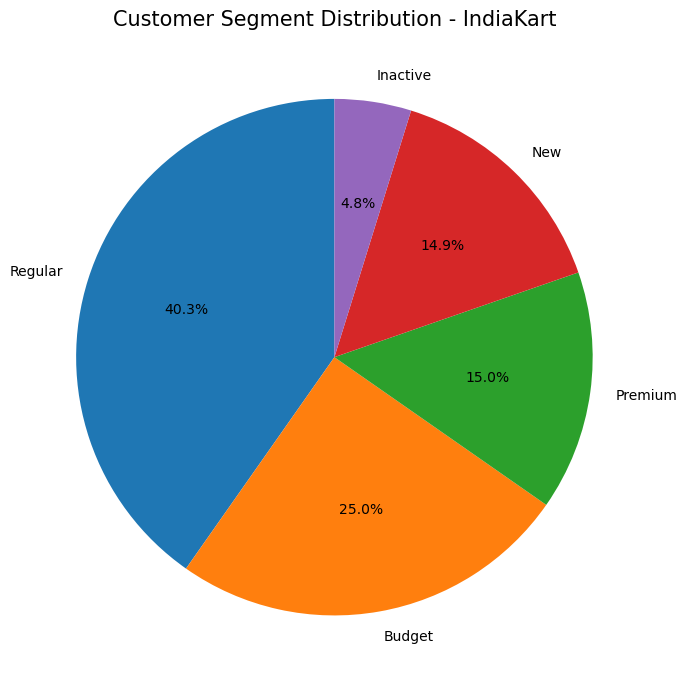

,Customer Count,Percentage (%)
segment,,
Regular,4026,40.26
Budget,2505,25.05
Premium,1501,15.01
New,1488,14.88
Inactive,480,4.80


In [17]:

# KPI 6: Customer Segment Distribution

# Count unique customers in each segment
segment_counts = (
    customers.groupby('segment')['customer_id']
    .nunique()
    .sort_values(ascending=False)
)

# Calculate percentage of customers
segment_percentages = segment_counts / segment_counts.sum() * 100

# Create pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segment Distribution - IndiaKart', fontsize=15)
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI6_Customer_Segment_Distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display counts and percentages
segment_summary = pd.DataFrame({
    'Customer Count': segment_counts,
    'Percentage (%)': segment_percentages
})

display(segment_summary.round(2))



### Observations

1. Regular customers form the largest segment, accounting for approximately 40.3% of the customer base. This indicates that regular customers represent the largest share of IndiaKart's customers.

2. Budget customers contribute approximately 25.3%, while Premium customers account for 15.0%. These segments represent different customer groups that may respond to different pricing and marketing strategies.

3. New customers account for 14.9%, while Inactive customers represent 4.8%. IndiaKart could focus on converting new customers into repeat buyers and re-engaging inactive customers.



## KPI 7: Payment Method Usage

### Objective
Analyze the popularity of different payment methods used for IndiaKart orders.

### Business Questions
- Which payment method is used most frequently?
- Which payment method is least popular?
- How are orders distributed across payment methods?

### Methodology
Group orders by payment method, count unique order IDs, and compare the results using a bar chart.

### Columns Used
- `order_id`: Unique order identifier
- `payment_method`: Payment method selected for the order

### Expected Outcome
Identify the most frequently used payment methods and understand customer payment preferences.


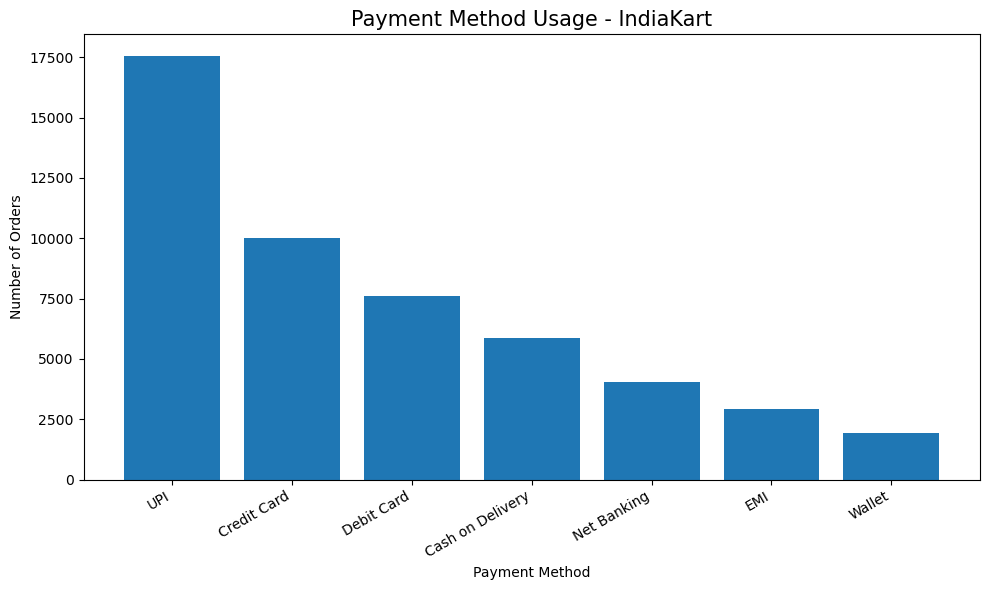

,Order Count,Percentage (%)
payment_method,,
UPI,17570,35.14
Credit Card,10007,20.01
Debit Card,7624,15.25
Cash on Delivery,5883,11.77
Net Banking,4026,8.05
EMI,2943,5.89
Wallet,1947,3.89


Most popular payment method: UPI
Least popular payment method: Wallet


In [18]:

# KPI 7: Payment Method Usage

# Count unique orders by payment method
payment_counts = (
    orders.groupby('payment_method')['order_id']
    .nunique()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    payment_counts.index,
    payment_counts.values
)

plt.title('Payment Method Usage - IndiaKart', fontsize=15)
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI7_Payment_Method_Usage.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display counts and percentages
payment_summary = pd.DataFrame({
    'Order Count': payment_counts,
    'Percentage (%)': payment_counts / payment_counts.sum() * 100
})

display(payment_summary.round(2))

print("Most popular payment method:", payment_counts.idxmax())
print("Least popular payment method:", payment_counts.idxmin())



### Observations

1. UPI is the most popular payment method, accounting for 35.14% of orders. This indicates a strong preference for UPI payments among IndiaKart customers.

2. Credit Cards account for 20.01% of orders, followed by Debit Cards at 15.25%. Together, these methods represent a substantial share of electronic payments.

3. Wallets are the least-used payment method, representing 3.89% of orders. IndiaKart could investigate customer preferences and potential opportunities to improve wallet adoption.



## KPI 8: Age Distribution of Customers

### Objective
Analyze the age distribution of IndiaKart customers to identify the age groups that shop most frequently.

### Business Questions
- Which age group has the highest number of customers?
- What is the overall age distribution of customers?
- Are customers concentrated in particular age ranges?

### Methodology
Use the customer dataset to create a histogram showing the distribution of customer ages. Group ages into intervals to identify the most common age ranges.

### Columns Used
- `age`: Customer age
- `customer_id`: Unique customer identifier

### Expected Outcome
Identify the most common customer age group and understand the age profile of IndiaKart's customer base.


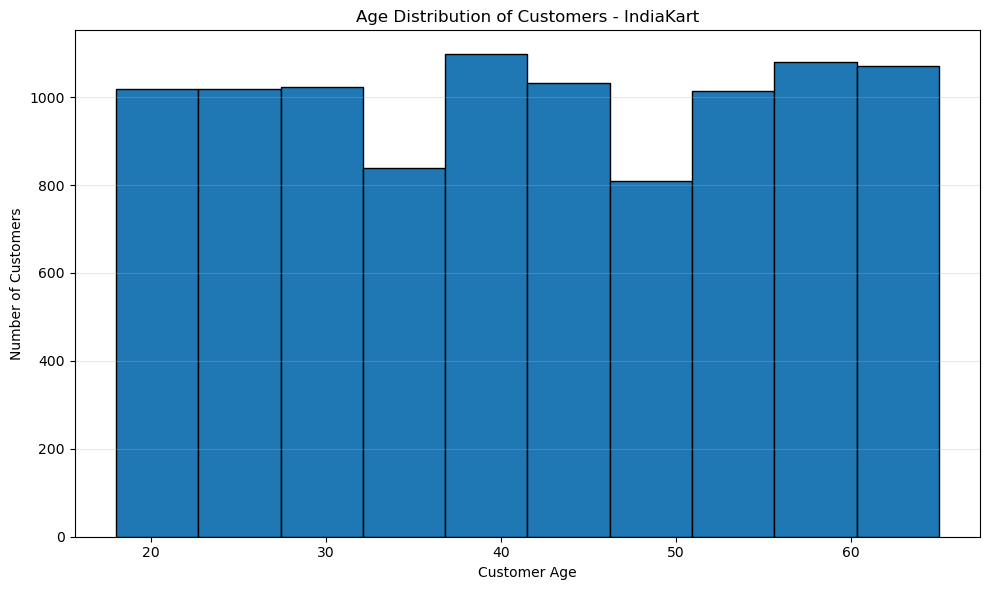

Average customer age: 41.7
Most common age: 35
Minimum age: 18
Maximum age: 65


In [21]:

# KPI 8: Age Distribution of Customers

# Remove missing ages
age_data = customers['age'].dropna()

# Create histogram
plt.figure(figsize=(10, 6))
plt.hist(age_data, bins=10, edgecolor='black')

plt.title('Age Distribution of Customers - IndiaKart')
plt.xlabel('Customer Age')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI8_Age_Distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display summary
print("Average customer age:", round(age_data.mean(), 1))
print("Most common age:", age_data.mode().iloc[0])
print("Minimum age:", age_data.min())
print("Maximum age:", age_data.max())



### Observations

1. The average customer age is approximately **41.7 years**, indicating that the customer base includes a substantial number of middle-aged shoppers.

2. Customer ages range from **18 to 68 years**. The histogram shows a fairly broad distribution across age groups, without one age range overwhelmingly dominating.

3. The tallest histogram bar represents the age interval with the highest customer count. The business can use this distribution to understand its customer demographics and tailor marketing campaigns to different age groups.



## KPI 9: Return Reasons

### Objective
Identify the most common reasons customers return products.

### Business Questions
- What are the most frequent return reasons?
- Which return reasons account for the largest number of returns?
- Are there recurring issues that may require operational or product improvements?

### Methodology
Group return records by return reason, count the number of returns for each reason, and display the results using a bar chart.

### Columns Used
- `return_reason`: Reason for returning the product (confirm the exact column name in the dataset)
- `return_id`: Unique return identifier, if available

### Expected Outcome
Identify the most common return reasons and highlight potential areas for improvement in product quality, fulfilment, or customer experience.


In [22]:
print(returns.columns.tolist())
display(returns.head())

['return_id', 'order_id', 'customer_id', 'return_date', 'reason', 'return_amount', 'refund_status', 'refund_date', 'return_condition', 'remarks']


,return_id,order_id,customer_id,return_date,reason,return_amount,refund_status,refund_date,return_condition,remarks
0,RET00001,ORD000015,CUST05470,23-12-2024,Size Issue,24167.33,Pending,30-12-2024,Damaged,Customer initiated return within 7 day window
1,RET00002,ORD000017,CUST07581,01-11-2023,Defective Product,11698.27,Refunded,06-11-2023,Damaged,Customer initiated return within 7 day window
2,RET00003,ORD000038,CUST05691,01-05-2025,Wrong Product Delivered,11147.74,Refunded,06-05-2025,Damaged,Customer initiated return within 7 day window
3,RET00004,ORD000054,CUST03170,20-06-2025,Duplicate Order,9284.55,Refunded,24-06-2025,Acceptable,Customer initiated return within 7 day window
4,RET00005,ORD000072,CUST09318,16-03-2025,Duplicate Order,36912.59,Refunded,23-03-2025,Good,Customer initiated return within 7 day window


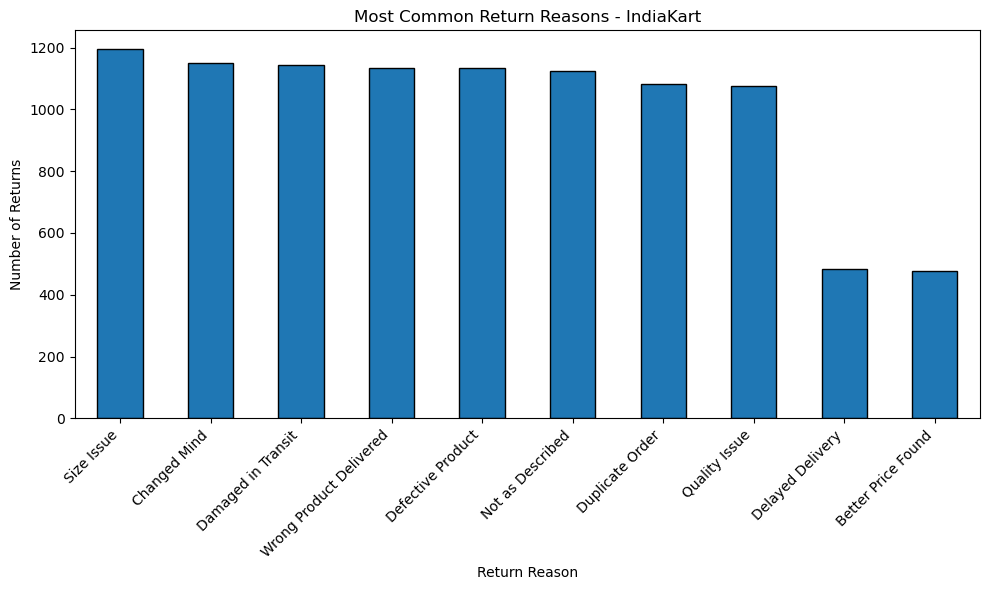

,Number of Returns
reason,
Size Issue,1196
Changed Mind,1150
Damaged in Transit,1143
Wrong Product Delivered,1135
Defective Product,1134
Not as Described,1125
Duplicate Order,1081
Quality Issue,1075
Delayed Delivery,484


Most common return reason: Size Issue
Number of returns: 1196


In [23]:

# KPI 9: Return Reasons

# Count returns by reason
return_counts = returns['reason'].value_counts().sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(10, 6))
return_counts.plot(kind='bar', edgecolor='black')

plt.title('Most Common Return Reasons - IndiaKart')
plt.xlabel('Return Reason')
plt.ylabel('Number of Returns')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI9_Return_Reasons.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display return counts
display(return_counts.to_frame(name='Number of Returns'))

print("Most common return reason:", return_counts.idxmax())
print("Number of returns:", return_counts.max())



### Observations

1. **Size Issue** is the most common return reason, with 1,196 returns, followed by Changed Mind (1,150) and Damaged in Transit (1,143).

2. Wrong Product Delivered (1,135), Defective Product (1,134), and Not as Described (1,125) also account for substantial returns. These reasons suggest opportunities to improve order accuracy, packaging, and product descriptions.

3. Delayed Delivery (484) and Better Price Found (477) are the least common return reasons. IndiaKart should prioritize addressing the leading return causes to improve customer satisfaction and potentially reduce return-related costs.



## KPI 10: Average Order Value (AOV) by Customer Segment

### Objective
Compare the average order value across Premium, Regular, and Budget customer segments.

### Business Questions
- Which customer segment has the highest average order value?
- Do Premium customers spend more per order than Regular and Budget customers?
- How does average spending differ across customer segments?

### Methodology
Merge order data with customer segment information using `customer_id`. Calculate the average `final_amount` for each segment and display the results using a bar chart.

### Columns Used
- `customer_id`: Unique customer identifier
- `segment`: Customer segment in the customers dataset
- `final_amount`: Final amount paid for an order

### Expected Outcome
Identify which customer segment has the highest average order value and understand differences in spending behavior across segments.


In [24]:

print("Customer segment column:", customers['segment'].unique())
print("Order amount column: final_amount")
print("Order customer column: customer_id")


Customer segment column: ['New' 'Budget' 'Regular' 'Premium' 'Inactive']
Order amount column: final_amount
Order customer column: customer_id


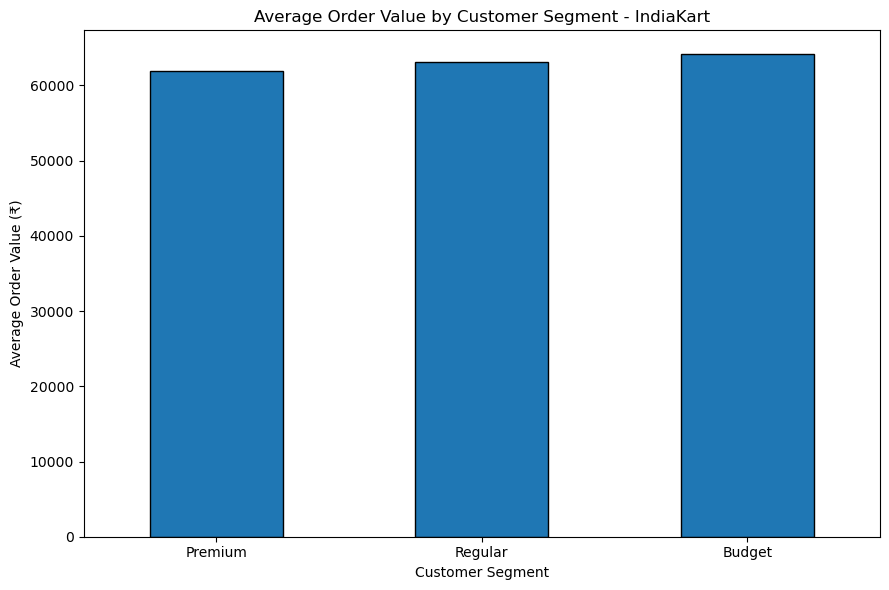

,Average Order Value (₹)
segment,
Premium,61876.90
Regular,63123.55
Budget,64124.56


Highest AOV segment: Budget
Highest AOV: 64124.56


In [25]:

# KPI 10: Average Order Value by Customer Segment

# Merge orders with customer segment information
orders_with_segment = orders.merge(
    customers[['customer_id', 'segment']],
    on='customer_id',
    how='left'
)

# Keep the three required customer segments
required_segments = ['Premium', 'Regular', 'Budget']

segment_orders = orders_with_segment[
    orders_with_segment['segment'].isin(required_segments)
].copy()

# Calculate average order value for each segment
aov_by_segment = (
    segment_orders.groupby('segment')['final_amount']
    .mean()
    .reindex(required_segments)
)

# Create bar chart
plt.figure(figsize=(9, 6))
aov_by_segment.plot(kind='bar', edgecolor='black')

plt.title('Average Order Value by Customer Segment - IndiaKart')
plt.xlabel('Customer Segment')
plt.ylabel('Average Order Value (₹)')
plt.xticks(rotation=0)
plt.tight_layout()

# Save chart as PNG
plt.savefig(
    os.path.join(charts_dir, 'KPI10_AOV_by_Segment.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display results
display(aov_by_segment.to_frame(name='Average Order Value (₹)').round(2))

print("Highest AOV segment:", aov_by_segment.idxmax())
print("Highest AOV:", round(aov_by_segment.max(), 2))



### Observations

1. The **Budget segment** has the highest average order value at ₹64,124.56, followed by Regular customers at ₹63,123.55 and Premium customers at ₹61,876.90.

2. Premium customers do not have the highest average order value in this dataset. Budget customers spend approximately ₹2,248 more per order than Premium customers on average.

3. IndiaKart can investigate purchasing patterns across segments and tailor product recommendations and promotions based on actual spending behavior rather than assuming Premium customers always spend more.
